# Bell-state preparation with complex path-integral control

Numerical instance of the two-qubit example: approximate preparation of
$$
\lvert\Phi^+\rangle=\frac{\lvert00\rangle+\lvert11\rangle}{\sqrt2}
$$
from $\lvert00\rangle$, with an entangling drift, local $X$/$Y$ controls, and generalized amplitude damping at strictly positive rates.

Local controls and local jump channels do not create entanglement, so the drift is $H_0=J\sigma_1^z\sigma_2^z$ with $J\neq0$. The controls are $H_{ai}=\sigma_i^a$ for $a\in\{x,y\}$ and $i\in\{1,2\}$. The jump operators are the local ladder operators $\sigma_i^\pm=(\sigma_i^x\pm i\sigma_i^y)/2$, with rates $\gamma_i^\pm>0$ and
$$
D=\mathrm{diag}(\gamma_1^+,\gamma_1^-,\gamma_2^+,\gamma_2^-).
$$
The matching matrix is the direct sum of two copies of the single-qubit transfer matrix,
$$
G_i=\begin{pmatrix}-i&-1\\-i&1\end{pmatrix},
\qquad
G=G_1\oplus G_2,
\qquad
\widehat R=G^\dagger D^{-1}G=\widehat R_1\oplus\widehat R_2.
$$
Each block is $\widehat R_i=\begin{pmatrix}r_i&-i\Delta r_i\\ i\Delta r_i& r_i\end{pmatrix}$ with $r_i=r_i^++r_i^-$, $\Delta r_i=r_i^+-r_i^-$, and $r_i^\pm=(\gamma_i^\pm)^{-1}$. Real pulses therefore see the diagonal kernel $\mathrm{Re}\,\widehat R=\mathrm{diag}(r_1,r_1,r_2,r_2)$. Unequal rates are allowed: only the sums $r_i$ enter that kernel, while the differences $\Delta r_i$ enter the controlled innovation $dB=G^\dagger D^{-1}dW$.

The bidirectional dissipator is positivity improving, so the average state at any $T>0$ is full rank. $\lvert\Phi^+\rangle$ is a fidelity target, not an exactly reachable pure state. The iteration below is the piecewise-constant cross-entropy update, scored on the linear stochastic Schrödinger equation and checked afterwards on the Lindblad equation.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

jax.config.update("jax_enable_x64", True)

SX = jnp.array([[0, 1], [1, 0]], dtype=jnp.complex128)
SY = jnp.array([[0, -1j], [1j, 0]], dtype=jnp.complex128)
SZ = jnp.array([[1, 0], [0, -1]], dtype=jnp.complex128)
SP = 0.5 * (SX + 1j * SY)
SM = 0.5 * (SX - 1j * SY)
I2 = jnp.eye(2, dtype=jnp.complex128)
G_PAIR = jnp.array([[-1j, -1.0], [-1j, 1.0]], dtype=jnp.complex128)


def kron(a, b):
    return jnp.kron(a, b)


def transfer_matrix():
    """G = G_1 ⊕ G_2, shape (noise, control)."""
    g = jnp.zeros((4, 4), dtype=jnp.complex128)
    return g.at[:2, :2].set(G_PAIR).at[2:, 2:].set(G_PAIR)


def rhat_blocks(gammas):
    """Return R̂ and the paper's (r_i, Δr_i) for each qubit."""
    g = transfer_matrix()
    rhat = g.conj().T @ jnp.diag(1.0 / gammas) @ g
    rates = jnp.reshape(gammas, (2, 2))
    r_plus, r_minus = 1.0 / rates[:, 0], 1.0 / rates[:, 1]
    return rhat, r_plus + r_minus, r_plus - r_minus


def bell_model(coupling, rates):
    """ZZ drift, local X/Y controls, generalized amplitude damping.

    `rates` is (γ1+, γ1-, γ2+, γ2-), every entry strictly positive.
    """
    rates = jnp.asarray(rates, dtype=jnp.float64)
    return dict(
        h0=coupling * kron(SZ, SZ),
        hs=jnp.stack([kron(SX, I2), kron(SY, I2), kron(I2, SX), kron(I2, SY)]),
        cs=jnp.stack([kron(SP, I2), kron(SM, I2), kron(I2, SP), kron(I2, SM)]),
        gammas=rates,
        psi0=jnp.array([1.0, 0.0, 0.0, 0.0], dtype=jnp.complex128),
        target=jnp.array([1.0, 0.0, 0.0, 1.0], dtype=jnp.complex128) / jnp.sqrt(2.0),
        labels=(r"$u_{x1}$", r"$u_{y1}$", r"$u_{x2}$", r"$u_{y2}$"),
    )


def matching_residual(psi, hs, cs, g):
    """Columns of g2 are C_a ψ and columns of g1 are -i H_b ψ."""
    g2 = jnp.einsum("mij,j->im", cs, psi)
    g1 = -1j * jnp.einsum("mij,j->im", hs, psi)
    return g2, g1, jnp.linalg.norm(g2 @ g - g1)


model = bell_model(coupling=1.0, rates=(6e-3, 4e-3, 7e-3, 3e-3))
G = transfer_matrix()
Rhat, r_sum, r_diff = rhat_blocks(model["gammas"])

expected = jnp.zeros((4, 4), dtype=jnp.complex128)
for i in range(2):
    block = jnp.array(
        [[r_sum[i], -1j * r_diff[i]], [1j * r_diff[i], r_sum[i]]],
        dtype=jnp.complex128,
    )
    expected = expected.at[2 * i : 2 * i + 2, 2 * i : 2 * i + 2].set(block)
assert jnp.allclose(Rhat, expected)
assert jnp.allclose(jnp.real(Rhat), jnp.diag(jnp.repeat(r_sum, 2)))

# Operator matching holds on every state, including |00>, where two ladder
# columns vanish and the structural G need not equal the Moore-Penrose lift.
psi_dark = model["psi0"]
psi_generic = jnp.array([0.3, 0.4, 0.5, 0.6], dtype=jnp.complex128)
psi_generic = psi_generic / jnp.linalg.norm(psi_generic)
for psi in (psi_dark, psi_generic):
    g2, g1, residual = matching_residual(psi, model["hs"], model["cs"], G)
    g_ls = jnp.linalg.pinv(g2) @ g1
    assert float(residual) < 1e-10
    assert float(jnp.linalg.norm(g2 @ g_ls - g1)) < 1e-8

_, _, dark_residual = matching_residual(psi_dark, model["hs"], model["cs"], G)
g2_dark, g1_dark, _ = matching_residual(psi_dark, model["hs"], model["cs"], G)
g_ls_dark = jnp.linalg.pinv(g2_dark) @ g1_dark
print(
    f"rates γ = {tuple(float(g) for g in model['gammas'])}\n"
    f"r = {tuple(float(v) for v in r_sum)},  Δr = {tuple(float(v) for v in r_diff)}\n"
    f"matching residual at |00> = {float(dark_residual):.2e}\n"
    f"||G - g2+ g1|| at |00> = {float(jnp.linalg.norm(G - g_ls_dark)):.3f}"
)

rates γ = (0.006, 0.004, 0.007, 0.003)
r = (416.66666666666663, 476.19047619047615),  Δr = (-83.33333333333334, -190.47619047619045)
matching residual at |00> = 0.00e+00
||G - g2+ g1|| at |00> = 2.000


## Stochastic cost and the pulse update

The linear stochastic Schrödinger equation, an unraveling of the controlled Lindblad equation,
$$
d\psi_t=-i(H_0+H_u)\psi_t\,dt-\frac12\sum_a\gamma_a C_a^\dagger C_a\,\psi_t\,dt+\sum_a C_a\psi_t\,dW_a,
$$
is integrated with circular increments, $dW\,dW^\dagger=D\,dt$ and $dW\,dW^T=0$. Individual trajectories are unnormalized. For a deterministic open-loop pulse their mean $\bar\rho(t)=E[\psi_t\psi_t^\dagger]$ solves the Lindblad equation.

With terminal weight $Q>0$ and no running state cost, the path cost on $[0,T]$ is
$$
S=Q\,\langle\psi_T\rvert(I-\lvert\Phi^+\rangle\langle\Phi^+\rvert)\lvert\psi_T\rangle
+\int_0^T u_s^T\mathrm{Re}(\widehat R)\,u_s\,ds
+2\int_0^T u_s^T\mathrm{Re}(dB_s)\,.
$$
The quadratic control term does not depend on the noise, so it cancels in the normalized path weights. Those weights use a numerical temperature $\lambda$,
$$
\omega\propto\exp(-S/\lambda),
$$
so that the Monte Carlo average is not carried by a single trajectory. The reported cost is still the Lindblad objective at the physical rates,
$$
C[u]=Q\bigl(1-\langle\Phi^+\rvert\bar\rho(T)\lvert\Phi^+\rangle\bigr)
+\int_0^T u_s^T\mathrm{Re}(\widehat R)\,u_s\,ds.
$$

On a uniform piecewise-constant grid the cross-entropy update is
$$
\hat A_{k}=A_k+\mathrm{Re}(\widehat R)^{-1}
\mathrm{Re}\!\left(\frac{\langle\omega\,\Delta B_k\rangle}{\Delta\tau}\right).
$$
The sampler for the next round is the average of the last few candidates. That average only damps Monte Carlo noise in $\langle\omega\,\Delta B_k\rangle$.

In [2]:
def expand_pulses(pulses, n_steps):
    spp = n_steps // pulses.shape[-1]
    return jnp.repeat(pulses, spp, axis=-1)


def sample_noise(key, gammas, n_traj, n_steps, dt):
    """Circular increments. Each part has variance γ Δt / 2."""
    k1, k2 = jax.random.split(key)
    shape = (n_traj, gammas.shape[0], n_steps)
    z = jax.random.normal(k1, shape) + 1j * jax.random.normal(k2, shape)
    return jnp.sqrt(gammas * dt / 2.0)[None, :, None] * z


def jump_generators(cs):
    return jnp.einsum("mji,mjk->mik", jnp.conjugate(cs), cs)


@jax.jit
def rollout(psi0, pulses, dw, dt, gammas, h0, hs, cs, target, q):
    """Euler step of the linear SSE, stored as a direction and a real scale.

    The terminal cost is the unnormalized infidelity
    Q * ||ψ||^2 * (1 - |<Φ+|ψ̂>|^2). `re_db` stores Re(dB) at each step.
    """
    n_steps = dw.shape[-1]
    u_t = expand_pulses(pulses, n_steps)
    g = transfer_matrix()
    re_db = jnp.real(jnp.einsum("cm,m,bmt->bct", g.conj().T, 1.0 / gammas, dw))
    cdags = jump_generators(cs)
    psi = jnp.broadcast_to(psi0, (dw.shape[0], psi0.shape[0])).astype(jnp.complex128)
    scale = jnp.ones((dw.shape[0],))

    def body(carry, inputs):
        psi_hat, scale = carry
        u, dw_t = inputs
        h = h0 + jnp.einsum("a,aij->ij", u, hs)
        ell = -1j * h - 0.5 * jnp.einsum("b,bij->ij", gammas, cdags)
        incr = psi_hat + dt * (ell @ psi_hat[..., None])[..., 0]
        incr = incr + jnp.einsum("mij,tj,tm->ti", cs, psi_hat, dw_t)
        nrm = jnp.maximum(jnp.linalg.norm(incr, axis=-1), 1e-30)
        return (incr / nrm[:, None], scale * nrm), None

    (psi_hat, scale), _ = jax.lax.scan(
        body, (psi, scale), (u_t.T, jnp.moveaxis(dw, -1, 0))
    )
    overlap = jnp.einsum("i,ti->t", jnp.conjugate(target), psi_hat)
    fidelity_hat = jnp.real(overlap * jnp.conjugate(overlap))
    phi = q * scale**2 * (1.0 - fidelity_hat)
    cross = 2.0 * jnp.einsum("ct,bct->b", u_t, re_db)
    return phi, cross, re_db, psi_hat, scale


def boltzmann_weights(cost, lam):
    centered = cost - jnp.min(cost)
    w = jnp.exp(-centered / lam)
    w = w / jnp.sum(w)
    ess = float(1.0 / jnp.sum(w**2))
    return w, ess


def pulse_update(pulses, re_db, weights, dt):
    """ΔA_k = Re(R̂)^{-1} Re(<ω ΔB_k> / Δτ)."""
    n_steps = re_db.shape[-1]
    n_pulses = pulses.shape[-1]
    spp = n_steps // n_pulses
    delta_b = re_db.reshape(re_db.shape[0], re_db.shape[1], n_pulses, spp).sum(-1)
    mean_b = jnp.einsum("b,bcp->cp", weights, delta_b) / (dt * spp)
    kernel = jnp.real(rhat_blocks(model["gammas"])[0])
    return jnp.linalg.solve(kernel, mean_b)


def fluence(pulses, n_steps, dt):
    u_t = expand_pulses(pulses, n_steps)
    kernel = jnp.real(rhat_blocks(model["gammas"])[0])
    return float(jnp.einsum("ct,cd,dt->", u_t, kernel, u_t) * dt)


def concurrence(rho):
    sy = np.array([[0, -1j], [1j, 0]], dtype=np.complex128)
    yy = np.kron(sy, sy)
    ev = np.linalg.eigvals(rho @ (yy @ rho.conj() @ yy))
    lam = np.sort(np.sqrt(np.clip(np.real(ev), 0.0, None)))[::-1]
    return float(max(0.0, lam[0] - lam[1] - lam[2] - lam[3]))


def lindblad_trajectory(pulses, n_steps, dt, rho0):
    """RK4 record of ρ̄. Fidelity is <Φ+|ρ|Φ+>."""
    u_t = np.asarray(expand_pulses(jnp.asarray(pulses), n_steps))
    gammas = np.asarray(model["gammas"])
    h0 = np.asarray(model["h0"])
    hs = np.asarray(model["hs"])
    cs = np.asarray(model["cs"])
    target = np.asarray(model["target"])
    cdags = np.einsum("mji,mjk->mik", np.conjugate(cs), cs)
    rho = np.asarray(rho0, dtype=np.complex128)
    fids = np.empty(n_steps)
    conc = np.empty(n_steps)
    pops = np.empty((n_steps, rho.shape[0]))
    sub, ddt = 4, dt / 4.0

    def rhs(rho, h):
        comm = -1j * (h @ rho - rho @ h)
        diss = np.zeros_like(rho)
        for b in range(len(gammas)):
            c = cs[b]
            diss += gammas[b] * (
                c @ rho @ c.conj().T - 0.5 * (cdags[b] @ rho + rho @ cdags[b])
            )
        return comm + diss

    for k in range(n_steps):
        h = h0 + np.einsum("a,aij->ij", u_t[:, k], hs)
        for _ in range(sub):
            k1 = rhs(rho, h)
            k2 = rhs(rho + 0.5 * ddt * k1, h)
            k3 = rhs(rho + 0.5 * ddt * k2, h)
            k4 = rhs(rho + ddt * k3, h)
            rho = rho + (ddt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
        rho = 0.5 * (rho + rho.conj().T)
        fids[k] = float(np.real(np.vdot(target, rho @ target)))
        conc[k] = concurrence(rho)
        pops[k] = np.real(np.diag(rho))
    return dict(fidelity=fids, concurrence=conc, populations=pops, rho=rho)


def train(pulses0, time, q, lam, n_traj, n_steps, n_iterations, seed, smooth=3):
    if n_steps % pulses0.shape[-1] != 0:
        raise ValueError("n_steps must be divisible by the number of pulses")
    dt = time / n_steps
    key = jax.random.PRNGKey(seed)
    pulses = jnp.asarray(pulses0)
    psi0 = np.asarray(model["psi0"])
    rho0 = np.outer(psi0, psi0.conj())
    buffer = []
    history = {k: [] for k in ("fidelity", "concurrence", "cost", "fluence", "ess")}

    for p in range(n_iterations):
        key, sub = jax.random.split(key)
        dw = sample_noise(sub, model["gammas"], n_traj, n_steps, dt)
        phi, cross, re_db, _, _ = rollout(
            model["psi0"], pulses, dw, dt, model["gammas"],
            model["h0"], model["hs"], model["cs"], model["target"], q,
        )
        weights, ess = boltzmann_weights(phi + cross, lam)
        candidate = np.asarray(pulses + pulse_update(pulses, re_db, weights, dt))
        buffer.append(candidate)
        buffer = buffer[-smooth:]
        pulses = jnp.asarray(np.mean(np.stack(buffer), axis=0))

        final = lindblad_trajectory(pulses, n_steps, dt, rho0)
        fid = float(final["fidelity"][-1])
        conc = float(final["concurrence"][-1])
        effort = fluence(pulses, n_steps, dt)
        history["fidelity"].append(fid)
        history["concurrence"].append(conc)
        history["cost"].append(q * (1.0 - fid) + effort)
        history["fluence"].append(effort)
        history["ess"].append(ess)
        if p % 5 == 0 or p == n_iterations - 1:
            print(
                f"iter {p:3d}  F={fid:.3f}  C={conc:.3f}  "
                f"cost={history['cost'][-1]:.1f}  ESS={ess:.0f}",
                flush=True,
            )

    for k, v in history.items():
        history[k] = np.asarray(v)
    learned = lindblad_trajectory(pulses, n_steps, dt, rho0)
    zero = lindblad_trajectory(jnp.zeros_like(pulses), n_steps, dt, rho0)
    return dict(pulses=np.asarray(pulses), history=history, learned=learned, zero=zero, dt=dt, time=time, q=q)

## A numerical check of the unraveling

Before the pulse search, one fixed control is integrated both ways. The sample mean of $\psi\psi^\dagger$ is the Euler unraveling; the comparison curve is an RK4 solution of the Lindblad equation. Agreement here is what makes the later fidelity a property of $\bar\rho$, rather than of one stochastic realization.

In [3]:
time, n_steps, n_check = 3.0, 160, 600
dt = time / n_steps
probe = 0.4 * jax.random.normal(jax.random.PRNGKey(1), (4, 8))
dw = sample_noise(jax.random.PRNGKey(2), model["gammas"], n_check, n_steps, dt)
_, _, _, psi_hat, scale = rollout(
    model["psi0"], probe, dw, dt, model["gammas"],
    model["h0"], model["hs"], model["cs"], model["target"], q=1.0,
)
outer = psi_hat[:, :, None] * jnp.conjugate(psi_hat[:, None, :])
rho_mc = jnp.mean(scale[:, None, None] ** 2 * outer, axis=0)
rho0 = np.outer(np.asarray(model["psi0"]), np.asarray(model["psi0"]).conj())
rho_lindblad = lindblad_trajectory(probe, n_steps, dt, rho0)["rho"]
gap = float(jnp.linalg.norm(rho_mc - rho_lindblad))
fid_mc = float(jnp.real(jnp.vdot(model["target"], rho_mc @ model["target"])))
fid_lindblad = float(np.real(np.vdot(model["target"], rho_lindblad @ model["target"])))
print(
    f"mean ||ψ||^2 = {float(jnp.mean(scale**2)):.4f}\n"
    f"F sample = {fid_mc:.4f}   F Lindblad = {fid_lindblad:.4f}\n"
    f"||ρ_sample - ρ_Lindblad||_F = {gap:.4f}"
)
assert abs(float(jnp.mean(scale**2)) - 1.0) < 0.15
assert abs(fid_mc - fid_lindblad) < 0.05
assert gap < 0.2

mean ||ψ||^2 = 1.0842
F sample = 0.2494   F Lindblad = 0.2325
||ρ_sample - ρ_Lindblad||_F = 0.0836


## Pulse search

The horizon is $T=3$, split into eight equal pieces and $160$ Euler steps. The rates are the unequal tuple checked above, $J=1$, $Q=15000$, and $\lambda=300$. $\lvert00\rangle$ is an eigenstate of $\sigma_1^z\sigma_2^z$, so a zero pulse never leaves the computational-basis product state; the search starts from a small random seed. Each iteration draws $1000$ trajectories.

In [4]:
_, pulse_key = jax.random.split(jax.random.PRNGKey(5))
pulses0 = 0.6 * jax.random.normal(pulse_key, (4, 8))
run = train(
    pulses0,
    time=3.0,
    q=15000.0,
    lam=300.0,
    n_traj=1000,
    n_steps=160,
    n_iterations=40,
    seed=0,
)
print(
    f"no control   F={run['zero']['fidelity'][-1]:.3f}  "
    f"concurrence={run['zero']['concurrence'][-1]:.3f}\n"
    f"learned      F={run['learned']['fidelity'][-1]:.3f}  "
    f"concurrence={run['learned']['concurrence'][-1]:.3f}  "
    f"cost={run['history']['cost'][-1]:.1f}"
)

iter   0  F=0.506  C=0.888  cost=9546.5  ESS=6
iter   5  F=0.675  C=0.909  cost=7007.2  ESS=6
iter  10  F=0.802  C=0.925  cost=5043.8  ESS=8
iter  15  F=0.877  C=0.932  cost=3917.7  ESS=124
iter  20  F=0.921  C=0.939  cost=3247.2  ESS=229
iter  25  F=0.946  C=0.945  cost=2868.0  ESS=395
iter  30  F=0.960  C=0.949  cost=2660.0  ESS=517
iter  35  F=0.968  C=0.950  cost=2531.0  ESS=591
iter  39  F=0.971  C=0.952  cost=2471.5  ESS=617
no control   F=0.490  concurrence=0.000
learned      F=0.971  concurrence=0.952  cost=2471.5


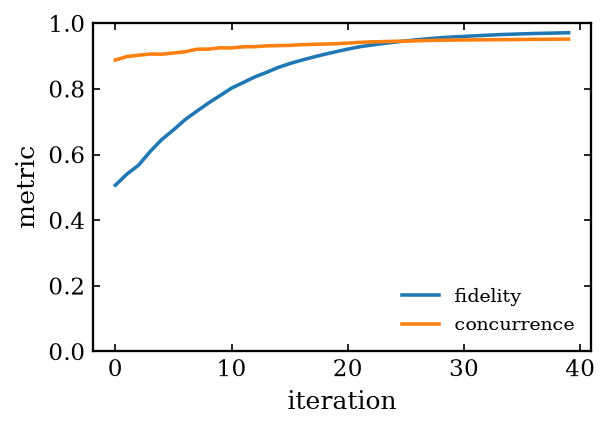

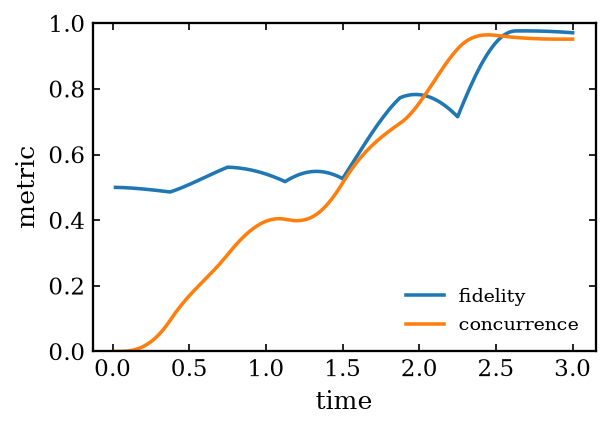

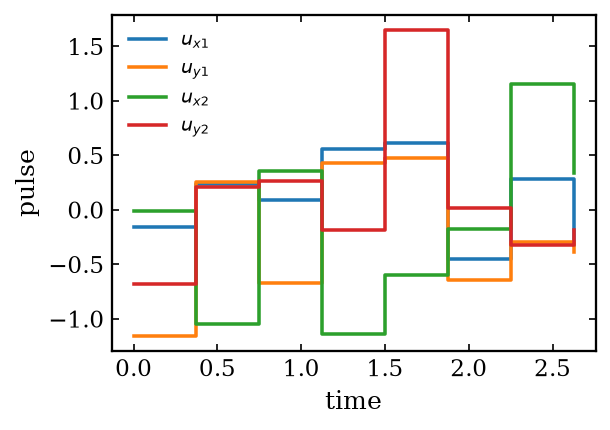

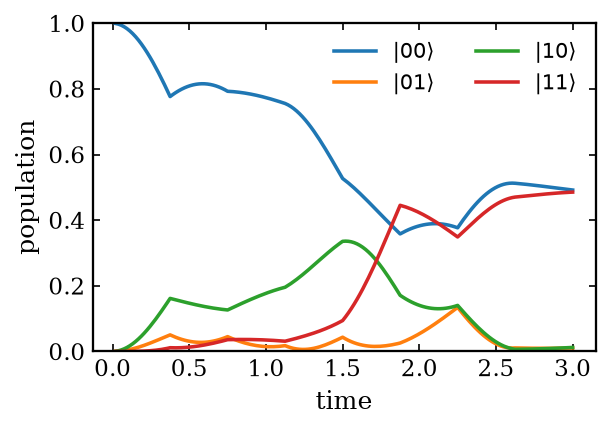

In [8]:
import matplotlib as mpl

# Set general rcParams for publication quality
mpl.rcParams.update({
    "font.size": 11,
    "font.family": "serif",
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "lines.linewidth": 1.7,
    "axes.linewidth": 1.1,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "axes.grid": False,
    "pdf.fonttype": 42,
})

t = np.linspace(run["dt"], run["time"], run["learned"]["fidelity"].size)
pulse_t = np.linspace(0, run["time"], run["pulses"].shape[-1], endpoint=False)
names = [r"$|00\rangle$", r"$|01\rangle$", r"$|10\rangle$", r"$|11\rangle$"]

# --- 1. Optimization History ---
fig1, ax1 = plt.subplots(figsize=(4.2, 3.0))
ax1.plot(run["history"]["fidelity"], color="C0", label="fidelity")
ax1.plot(run["history"]["concurrence"], color="C1", label="concurrence")
ax1.set_xlabel("iteration")
ax1.set_ylabel("metric")
ax1.set_ylim(0, 1)
ax1.spines[['top', 'right']].set_visible(True)
ax1.legend(frameon=False, fontsize=9, loc="lower right")
fig1.tight_layout()
fig1.savefig("fig_optimization_history.png", bbox_inches="tight", dpi=300)
plt.show()

# --- 2. Fidelity & Concurrence vs Time ---
fig2, ax2 = plt.subplots(figsize=(4.2, 3.0))
ax2.plot(t, run["learned"]["fidelity"], color="C0", label="fidelity")
ax2.plot(t, run["learned"]["concurrence"], color="C1", label="concurrence")
ax2.set_xlabel("time")
ax2.set_ylabel("metric")
ax2.set_ylim(0, 1)
ax2.spines[['top', 'right']].set_visible(True)
ax2.legend(frameon=False, fontsize=9, loc="lower right")
fig2.tight_layout()
fig2.savefig("fig_fidelity_concurrence.png", bbox_inches="tight", dpi=300)
plt.show()

# --- 3. Pulses vs Time ---
fig3, ax3 = plt.subplots(figsize=(4.2, 3.0))
for a, label in enumerate(model["labels"]):
    ax3.step(pulse_t, run["pulses"][a], where="post", label=label)
ax3.set_xlabel("time")
ax3.set_ylabel("pulse")
ax3.spines[['top', 'right']].set_visible(True)
ax3.legend(frameon=False, fontsize=9)
fig3.tight_layout()
fig3.savefig("fig_pulses.png", bbox_inches="tight", dpi=300)
plt.show()

# --- 4. Populations vs Time ---
fig4, ax4 = plt.subplots(figsize=(4.2, 3.0))
for i, name in enumerate(names):
    ax4.plot(t, run["learned"]["populations"][:, i], label=name)
ax4.set_xlabel("time")
ax4.set_ylabel("population")
ax4.set_ylim(0, 1)
ax4.legend(frameon=False, ncol=2, loc="upper right")
ax4.spines[['top', 'right']].set_visible(True)
fig4.tight_layout()
fig4.savefig("fig_populations.png", bbox_inches="tight", dpi=300)
plt.show()

The search raises the Lindblad fidelity and the concurrence together. The uncontrolled drift leaves $\lvert00\rangle$ essentially unentangled: $\sigma_1^z\sigma_2^z$ only supplies a phase, and the local dissipator is too weak to build $\lvert\Phi^+\rangle$ on this horizon. The learned pulse occupies both the even-parity populations and leaves the odd-parity populations small.

The terminal fidelity stays below one. That is the content of the positivity-improving bound: with $\gamma_i^\pm>0$ the average state is full rank, so a pure Bell state is not a reachable point of the Lindblad equation. The number reported here is the fidelity of that full-rank state, plus the fluence penalty in $C[u]$.

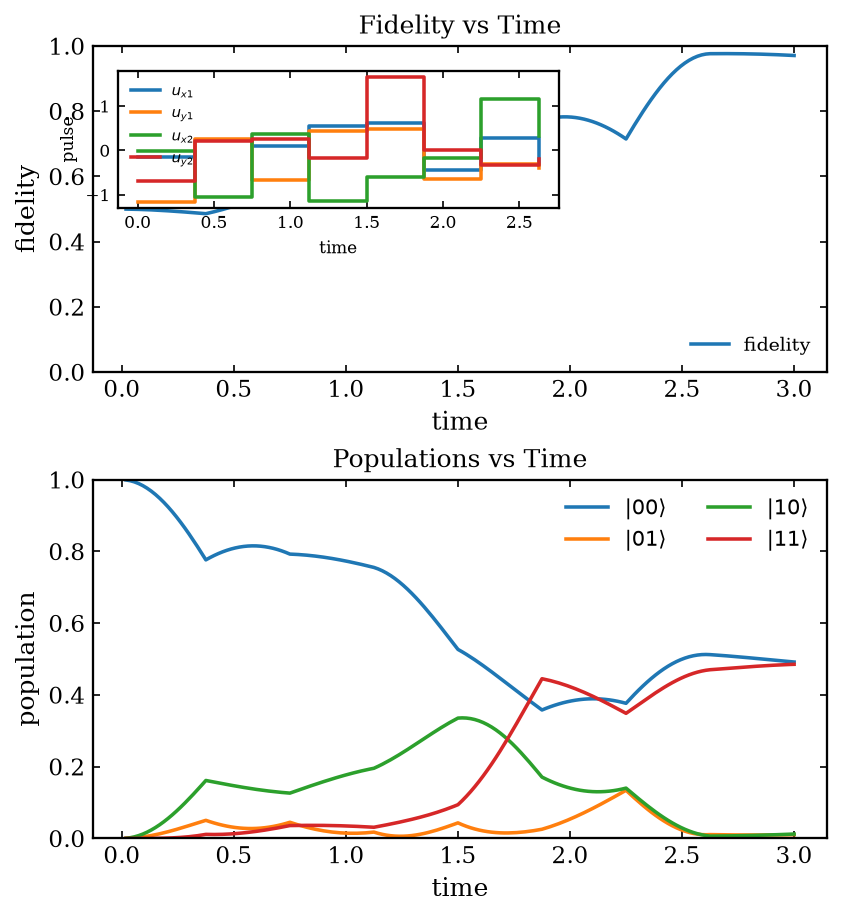

In [ ]:
import matplotlib as mpl

# Set general rcParams for publication quality
mpl.rcParams.update({
    "font.size": 11,
    "font.family": "serif",
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "lines.linewidth": 1.7,
    "axes.linewidth": 1.1,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "axes.grid": False,
    "pdf.fonttype": 42,
})

t = np.linspace(run["dt"], run["time"], run["learned"]["fidelity"].size)
pulse_t = np.linspace(0, run["time"], run["pulses"].shape[-1], endpoint=False)
names = [r"$|00\rangle$", r"$|01\rangle$", r"$|10\rangle$", r"$|11\rangle$"]

# --- Make two stacked plots: (1) Fidelity with pulse inset, (2) Populations vs Time ---

import matplotlib.patches as mpatches

fig, (ax_fid, ax_pop) = plt.subplots(2, 1, figsize=(5.5, 6.0), constrained_layout=True, gridspec_kw={'height_ratios': [1, 1.1]})

# (1) Fidelity vs Time with pulses as inset
ax_fid.plot(t, run["learned"]["fidelity"], color="C0", label="fidelity")
ax_fid.set_xlabel("time")
ax_fid.set_ylabel("fidelity")
ax_fid.set_ylim(0, 1)
ax_fid.spines[['top', 'right']].set_visible(True)
ax_fid.set_title("Fidelity vs Time", fontsize=12)
ax_fid.legend(frameon=False, fontsize=9, loc="lower right")

# Inset for control pulses
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
ax_inset = inset_axes(ax_fid, width="60%", height="42%", loc='upper left', borderpad=1.2)
for a, label in enumerate(model["labels"]):
    ax_inset.step(pulse_t, run["pulses"][a], where="post", label=label)
ax_inset.set_xlabel("time", fontsize=8)
ax_inset.set_ylabel("pulse", fontsize=8)
ax_inset.tick_params(axis='both', labelsize=8)
ax_inset.spines[['top', 'right']].set_visible(True)
# Only show legend on the inset if more than one control
if len(model["labels"]) > 1:
    ax_inset.legend(frameon=False, fontsize=7)

# (2) Populations vs Time
for i, name in enumerate(names):
    ax_pop.plot(t, run["learned"]["populations"][:, i], label=name)
ax_pop.set_xlabel("time")
ax_pop.set_ylabel("population")
ax_pop.set_ylim(0, 1)
ax_pop.legend(frameon=False, ncol=2, loc="lower right")
ax_pop.spines[['top', 'right']].set_visible(True)
ax_pop.set_title("Populations vs Time", fontsize=12)

fig.savefig("fig_fidelity_populations_with_pulse_inset.png", bbox_inches="tight", dpi=300)
plt.show()